# Classification Results — Iris

**Este notebook NO entrena modelos.**

Solo lee los JSON generados por `Notebooks/Classification/` y crea las figuras
para el documento y la defensa.

Archivos esperados en `Notebooks/Results/metrics/`:
`svm.json`, `rf.json`, `xgb.json`, `qsvm.json`, `qnn.json`, `vqc.json`


## Cargar métricas


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

cwd = Path.cwd()
if cwd.name == "Results":
    RESULTS_DIR = cwd
elif (cwd / "Notebooks" / "Results").exists():
    RESULTS_DIR = cwd / "Notebooks" / "Results"
else:
    RESULTS_DIR = cwd

FIGURES_DIR = RESULTS_DIR / "figures"
METRICS_DIR = RESULTS_DIR / "metrics"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED = {
    "SVM": "svm.json",
    "Random Forest": "rf.json",
    "XGBoost": "xgb.json",
    "QSVM": "qsvm.json",
    "QNN": "qnn.json",
    "VQC": "vqc.json",
}
ALL_MODELS = list(EXPECTED.keys())

results = {}
missing = []
for model, filename in EXPECTED.items():
    path = METRICS_DIR / filename
    if not path.exists():
        missing.append(str(path))
        continue
    results[model] = json.loads(path.read_text())

if missing:
    raise FileNotFoundError(
        "Faltan métricas. Ejecuta primero los notebooks de Classification.\n"
        + "\n".join(f" - {m}" for m in missing)
    )

print(f"Loaded {len(results)}/{len(EXPECTED)} from {METRICS_DIR}")
for m in ALL_MODELS:
    print(f"  {m}: test acc={results[m]['test']['accuracy']:.4f}")


Loaded 6/6 from /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Results/metrics
  SVM: test acc=0.9667
  Random Forest: test acc=0.9500
  XGBoost: test acc=0.9500
  QSVM: test acc=0.7333
  QNN: test acc=0.9333
  VQC: test acc=0.9500


## Tabla consolidada


In [2]:
rows = []
for name in ALL_MODELS:
    r = results[name]
    for split in ("train", "test"):
        rows.append({
            "model": name,
            "family": r["family"],
            "split": split,
            **{k: r[split].get(k) for k in ["accuracy", "precision", "recall", "f1", "auc"]},
            "train_time_s": r["train_time_s"],
            "inference_time_s": r["inference_time_s"],
        })

df = pd.DataFrame(rows)
df_test = df[df["split"] == "test"].set_index("model").loc[ALL_MODELS].reset_index()
df_train = df[df["split"] == "train"].set_index("model").loc[ALL_MODELS].reset_index()

summary = df_test[
    ["model", "family", "accuracy", "precision", "recall", "f1", "auc", "train_time_s", "inference_time_s"]
].copy()
summary["acc_gap"] = (
    df_train.set_index("model").loc[summary["model"], "accuracy"].to_numpy(dtype=float)
    - summary["accuracy"].to_numpy(dtype=float)
)
print(summary.round(4).to_string(index=False))

summary_path = METRICS_DIR / "iris_classification_summary.csv"
summary.to_csv(summary_path, index=False)
print("\nSaved:", summary_path)


        model    family  accuracy  precision  recall     f1    auc  train_time_s  inference_time_s  acc_gap
          SVM classical    0.9667     0.9697  0.9667 0.9666 0.9983        0.0014            0.0003   0.0111
Random Forest classical    0.9500     0.9507  0.9500 0.9500 0.9910        0.0570            0.0040   0.0500
      XGBoost classical    0.9500     0.9507  0.9500 0.9500 0.9829        0.1293            0.0013   0.0500
         QSVM   quantum    0.7333     0.7433  0.7333 0.7304 0.8825        0.0741            0.1078   0.2333
          QNN   quantum    0.9333     0.9360  0.9333 0.9332 0.9746        0.6897            0.0054   0.0222
          VQC   quantum    0.9500     0.9507  0.9500 0.9500    NaN       49.8703            0.1605  -0.0056

Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Results/metrics/iris_classification_summary.csv


## Estilo UNIR


In [3]:
UNIR_NAVY = "#0E4A75"
UNIR_AZUL = "#219BC3"
UNIR_GRIS = "#858591"
UNIR_CLARO = "#C0C0C8"

MODEL_COLORS = {
    "SVM": UNIR_NAVY,
    "Random Forest": "#1A6B9A",
    "XGBoost": "#3D8BB8",
    "QSVM": UNIR_AZUL,
    "QNN": "#5BB8D4",
    "VQC": "#8CCFE0",
}

plt.rcParams.update({
    "font.sans-serif": ["Arial", "DejaVu Sans", "Helvetica"],
    "axes.edgecolor": UNIR_CLARO,
    "grid.color": UNIR_CLARO,
    "grid.linestyle": "--",
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "figure.dpi": 150,
})

def savefig(name):
    path = FIGURES_DIR / name
    plt.savefig(path, bbox_inches="tight", facecolor="white")
    print("Saved:", path)
    plt.show()

def annotate_bars(ax, container, fmt="{:.2f}"):
    for bar in container:
        h = bar.get_height()
        if np.isnan(h):
            continue
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            h + 0.02,
            fmt.format(h),
            ha="center",
            va="bottom",
            fontsize=8,
            color=UNIR_GRIS,
        )

metric_cols = ["accuracy", "precision", "recall", "f1", "auc"]
metric_labels = ["Accuracy", "Precision", "Recall", "F1", "AUC"]


### 1. Métricas de test por modelo


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Results/figures/iris_test_metrics_by_model.png


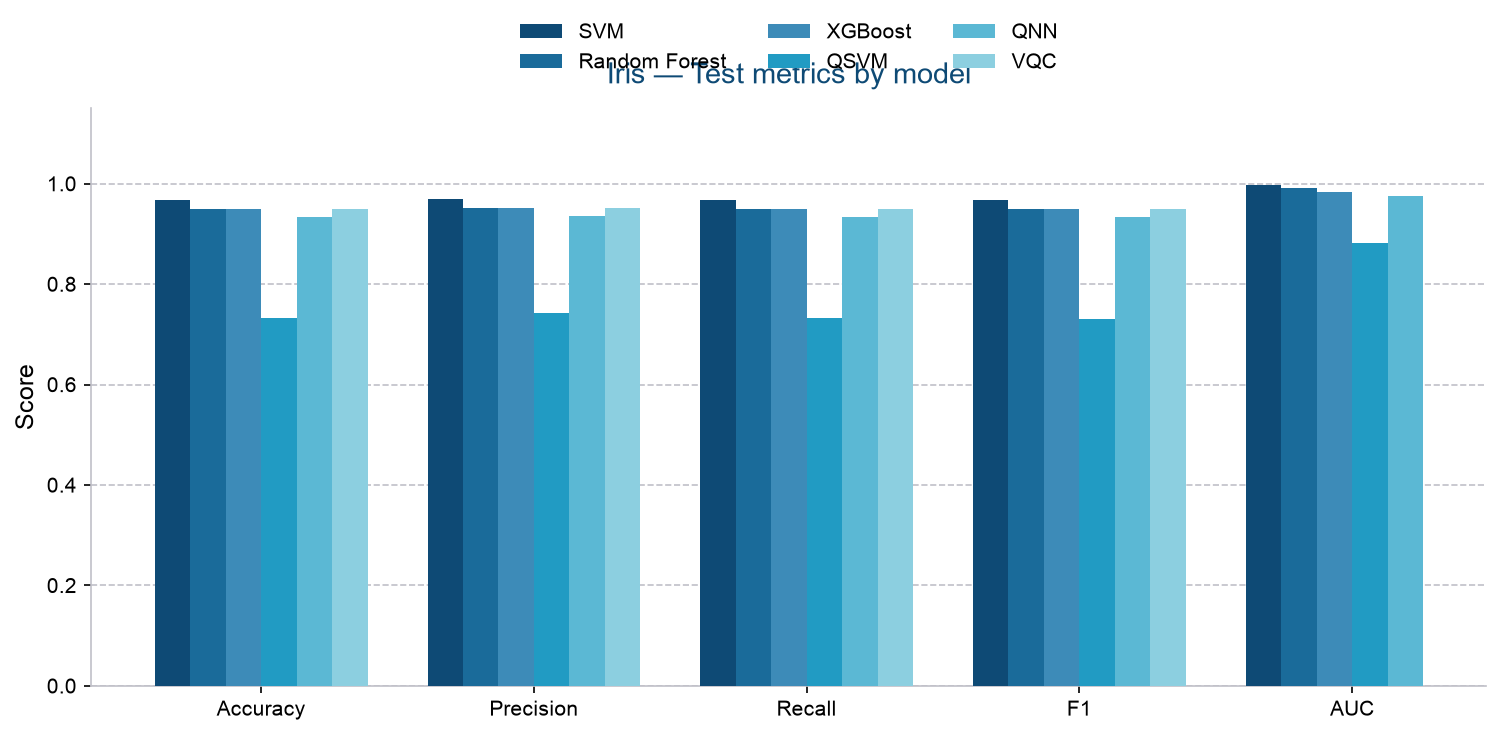

In [4]:
x = np.arange(len(metric_labels))
width = 0.13
fig, ax = plt.subplots(figsize=(12, 5))
for i, model in enumerate(ALL_MODELS):
    vals = df_test.set_index("model").loc[model, metric_cols].to_numpy(dtype=float)
    ax.bar(x + (i - 2.5) * width, vals, width, label=model, color=MODEL_COLORS[model], zorder=3)
ax.set_xticks(x)
ax.set_xticklabels(metric_labels)
ax.set_ylim(0, 1.15)
ax.set_ylabel("Score")
ax.set_title("Iris — Test metrics by model", color=UNIR_NAVY, pad=12)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.18))
ax.grid(axis="y", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
savefig("iris_test_metrics_by_model.png")


### 2. Train vs Test (Accuracy y F1)


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Results/figures/iris_train_vs_test.png


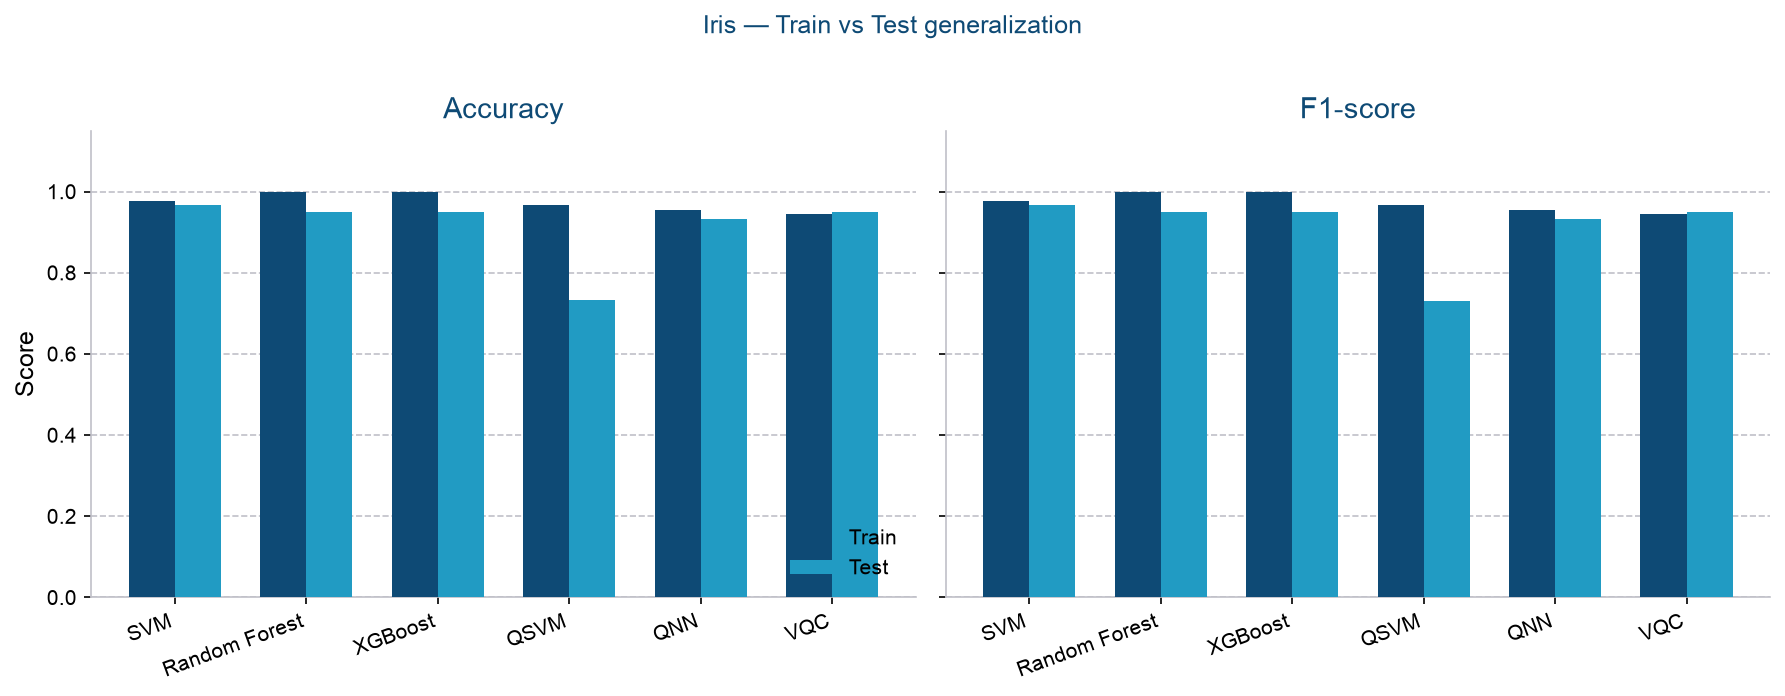

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, metric, title in zip(axs, ["accuracy", "f1"], ["Accuracy", "F1-score"]):
    x = np.arange(len(ALL_MODELS))
    width = 0.35
    train_vals = df_train.set_index("model").loc[ALL_MODELS, metric].to_numpy(dtype=float)
    test_vals = df_test.set_index("model").loc[ALL_MODELS, metric].to_numpy(dtype=float)
    ax.bar(x - width / 2, train_vals, width, label="Train", color=UNIR_NAVY, zorder=3)
    ax.bar(x + width / 2, test_vals, width, label="Test", color=UNIR_AZUL, zorder=3)
    ax.set_xticks(x)
    ax.set_xticklabels(ALL_MODELS, rotation=20, ha="right")
    ax.set_ylim(0, 1.15)
    ax.set_title(title, color=UNIR_NAVY)
    ax.grid(axis="y", zorder=0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if ax is axs[0]:
        ax.set_ylabel("Score")
        ax.legend(frameon=False, loc="lower right")
fig.suptitle("Iris — Train vs Test generalization", color=UNIR_NAVY, y=1.02)
fig.tight_layout()
savefig("iris_train_vs_test.png")


### 3. Clásicos vs cuánticos (media en test)


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Results/figures/iris_classical_vs_quantum.png


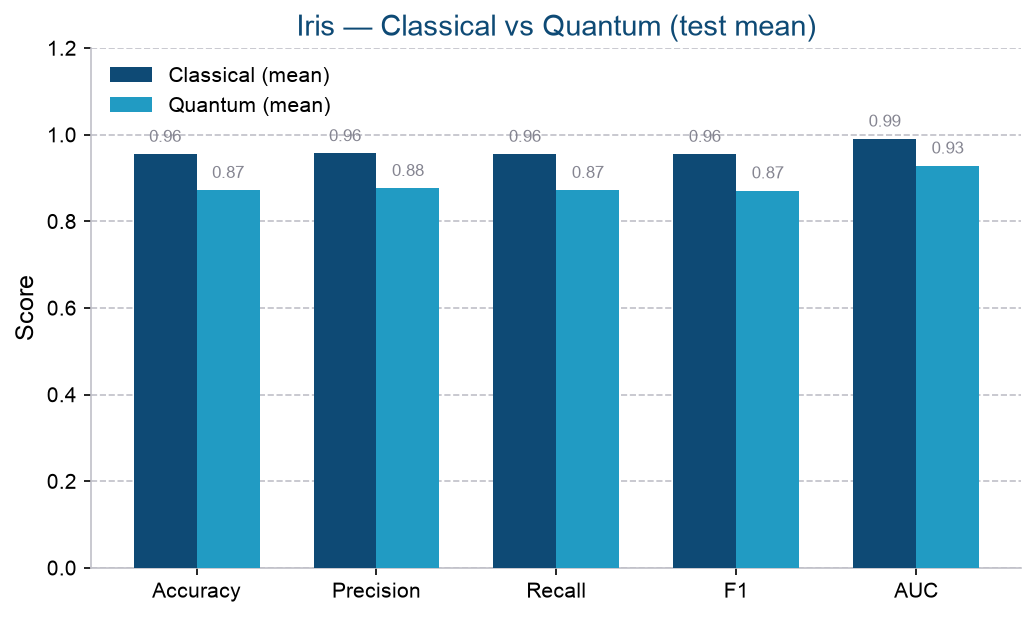

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(metric_labels))
width = 0.35
classical = np.nanmean(
    df_test[df_test["family"] == "classical"][metric_cols].to_numpy(dtype=float), axis=0
)
quantum = np.nanmean(
    df_test[df_test["family"] == "quantum"][metric_cols].to_numpy(dtype=float), axis=0
)
b1 = ax.bar(x - width / 2, classical, width, label="Classical (mean)", color=UNIR_NAVY, zorder=3)
b2 = ax.bar(x + width / 2, quantum, width, label="Quantum (mean)", color=UNIR_AZUL, zorder=3)
annotate_bars(ax, b1)
annotate_bars(ax, b2)
ax.set_xticks(x)
ax.set_xticklabels(metric_labels)
ax.set_ylim(0, 1.2)
ax.set_ylabel("Score")
ax.set_title("Iris — Classical vs Quantum (test mean)", color=UNIR_NAVY)
ax.legend(frameon=False)
ax.grid(axis="y", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
savefig("iris_classical_vs_quantum.png")


### 4. Gap de generalización (train − test)


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Results/figures/iris_generalization_gap.png


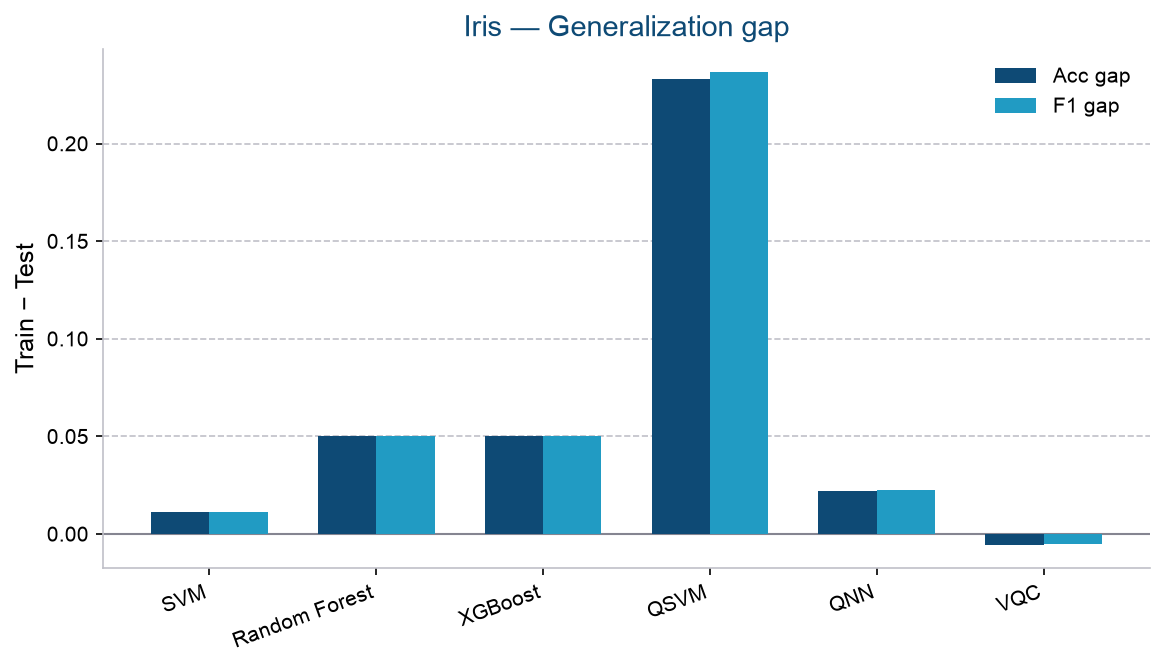

In [7]:
gap_acc = (
    df_train.set_index("model").loc[ALL_MODELS, "accuracy"].to_numpy(dtype=float)
    - df_test.set_index("model").loc[ALL_MODELS, "accuracy"].to_numpy(dtype=float)
)
gap_f1 = (
    df_train.set_index("model").loc[ALL_MODELS, "f1"].to_numpy(dtype=float)
    - df_test.set_index("model").loc[ALL_MODELS, "f1"].to_numpy(dtype=float)
)
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(ALL_MODELS))
width = 0.35
ax.bar(x - width / 2, gap_acc, width, label="Acc gap", color=UNIR_NAVY, zorder=3)
ax.bar(x + width / 2, gap_f1, width, label="F1 gap", color=UNIR_AZUL, zorder=3)
ax.axhline(0, color=UNIR_GRIS, lw=1)
ax.set_xticks(x)
ax.set_xticklabels(ALL_MODELS, rotation=20, ha="right")
ax.set_ylabel("Train − Test")
ax.set_title("Iris — Generalization gap", color=UNIR_NAVY)
ax.legend(frameon=False)
ax.grid(axis="y", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
savefig("iris_generalization_gap.png")


### 5. Tiempos de entrenamiento e inferencia


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Results/figures/iris_runtimes.png


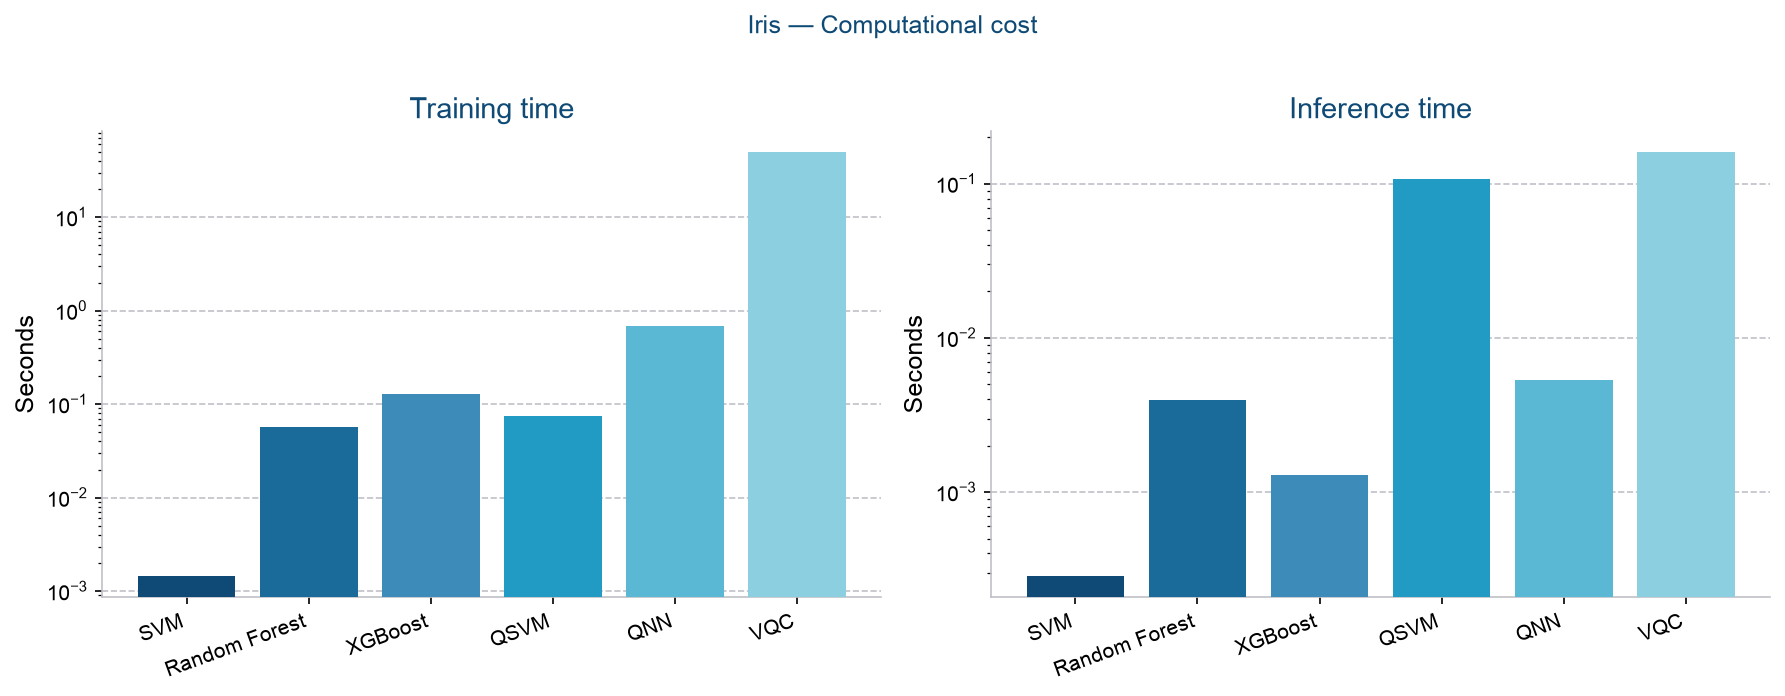

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
x = np.arange(len(ALL_MODELS))
train_times = df_test.set_index("model").loc[ALL_MODELS, "train_time_s"].to_numpy(dtype=float)
infer_times = df_test.set_index("model").loc[ALL_MODELS, "inference_time_s"].to_numpy(dtype=float)
colors = [MODEL_COLORS[m] for m in ALL_MODELS]
axs[0].bar(x, train_times, color=colors, zorder=3)
axs[0].set_xticks(x)
axs[0].set_xticklabels(ALL_MODELS, rotation=20, ha="right")
axs[0].set_ylabel("Seconds")
axs[0].set_title("Training time", color=UNIR_NAVY)
axs[0].set_yscale("log")
axs[0].grid(axis="y", zorder=0)
axs[0].spines["top"].set_visible(False)
axs[0].spines["right"].set_visible(False)
axs[1].bar(x, infer_times, color=colors, zorder=3)
axs[1].set_xticks(x)
axs[1].set_xticklabels(ALL_MODELS, rotation=20, ha="right")
axs[1].set_ylabel("Seconds")
axs[1].set_title("Inference time", color=UNIR_NAVY)
axs[1].set_yscale("log")
axs[1].grid(axis="y", zorder=0)
axs[1].spines["top"].set_visible(False)
axs[1].spines["right"].set_visible(False)
fig.suptitle("Iris — Computational cost", color=UNIR_NAVY, y=1.02)
fig.tight_layout()
savefig("iris_runtimes.png")


### 6. Heatmap resumen (test)


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Results/figures/iris_test_heatmap.png


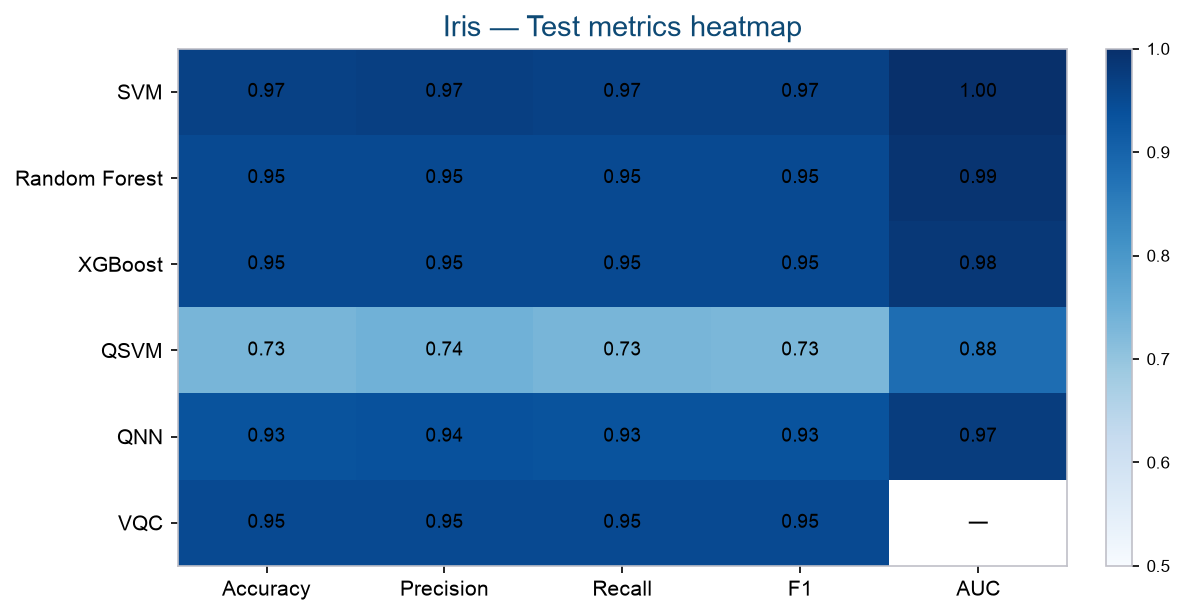

In [9]:
mat = df_test.set_index("model").loc[ALL_MODELS, metric_cols]
fig, ax = plt.subplots(figsize=(8, 4.2))
im = ax.imshow(mat.to_numpy(dtype=float), cmap="Blues", vmin=0.5, vmax=1.0, aspect="auto")
ax.set_xticks(range(len(metric_labels)))
ax.set_xticklabels(metric_labels)
ax.set_yticks(range(len(ALL_MODELS)))
ax.set_yticklabels(ALL_MODELS)
ax.set_title("Iris — Test metrics heatmap", color=UNIR_NAVY)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        val = mat.iloc[i, j]
        label = "—" if pd.isna(val) else f"{val:.2f}"
        ax.text(j, i, label, ha="center", va="center", color="black", fontsize=9)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=8)
fig.tight_layout()
savefig("iris_test_heatmap.png")


## Archivos generados


In [10]:
print("Metrics JSON:")
for p in sorted(METRICS_DIR.glob("*.json")):
    print(" -", p)
print("\nFigures:")
for p in sorted(FIGURES_DIR.glob("iris_*.png")):
    print(" -", p)


Metrics JSON:
 - /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Results/metrics/qnn.json
 - /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Results/metrics/qsvm.json
 - /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Results/metrics/rf.json
 - /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Results/metrics/svm.json
 - /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Results/metrics/vqc.json
 - /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Results/metrics/xgb.json

Figures:
 - /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Results/figures/iris_classical_vs_quantum.png
 - /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Results/figures/iris_generalization_gap.png
 - /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDa